# Basic TPS Setup with Toy Systems

This notebook demonstrates how to set up and run a basic TPS simulation using ops-setup with a toy potential.

No AIMMD learning is involved - this is pure Transition Path Sampling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import openpathsampling as paths
from pathlib import Path

# Import from ops-setup
from ops_setup.systems.examples.toy_systems import ToyTPSSetup, potential_1

## 1. Create the TPS Setup

We'll use potential_1, which is a 2D system with two minima.

In [2]:
# Setup TPS for toy potential 1
tps_setup = ToyTPSSetup(
    potential_name='wolfe-quapp',
    potential_kwargs={'n_harmonics': 0, 'rotation_degrees': 0, 'scale': 2},
    integrator_params={
        'dt': 0.05,
        'temperature': 1,
        'gamma': 2.5
    }
)

print(f"System: {tps_setup.system_name}")
print(f"MD Engine: {tps_setup.md_engine.name}")
print(f"States: {tps_setup.states}")

Setting up Langevin BAOAB integrator for toy system...
123
pot dimensions without oscillators: 2
harmonic oscillators omegas:
array([0., 0.])
Setting up Langevin BAOAB integrator for toy system...
Setting up toy engine for wolfe-quapp...
Creating snapshot template for toy system...
Defining states for wolfe-quapp...
System: wolfe-quapp
MD Engine: [ToyEngine]
States: (<openpathsampling.volume.CVDefinedVolume object at 0x3072aff50>, <openpathsampling.volume.CVDefinedVolume object at 0x16cacf860>)


## 2. Visualize the Potential Energy Surface

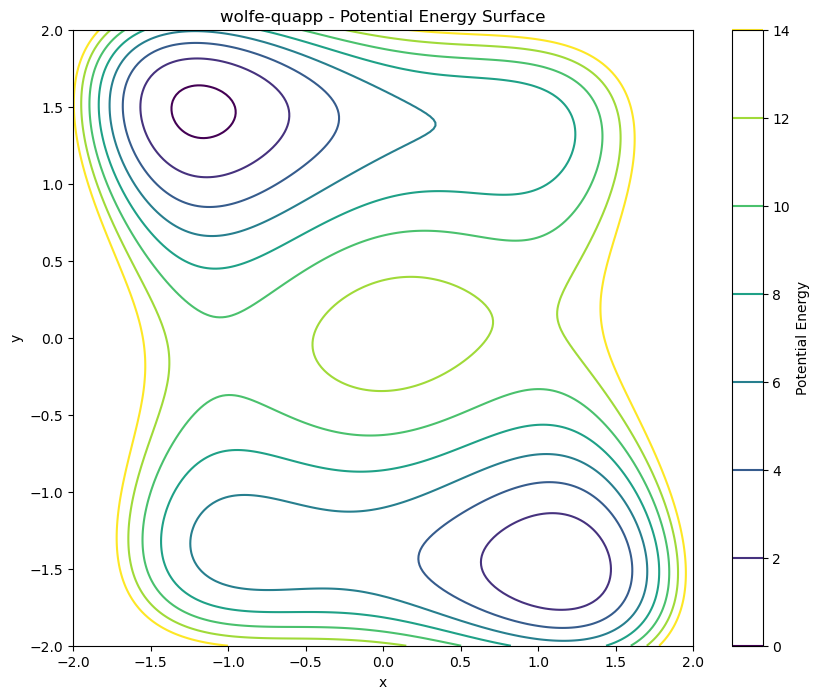

State A at: [-1.15  1.5 ]
State B at: [ 1.15 -1.5 ]
State boundary: 0.25


In [3]:
# Get the PES object
pes = tps_setup.pes

# Plot the 2D potential
x = np.linspace(pes.extent[0], pes.extent[1], 200)
y = np.linspace(pes.extent[2], pes.extent[3], 200)
X, Y, U = pes.plot_2d_pes(x, y)

plt.figure(figsize=(10, 8))
contours = plt.contour(X, Y, U, levels=pes.levels, cmap='viridis')
plt.colorbar(contours, label='Potential Energy')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'{tps_setup.system_name} - Potential Energy Surface')
plt.show()

print(f"State A at: {pes.state_A}")
print(f"State B at: {pes.state_B}")
print(f"State boundary: {pes.state_boundary}")

## 3. Create Initial Trajectory

We need an initial path that goes from state A to state B.

In [4]:
# Set engine for path movers
paths.PathMover.engine = tps_setup.md_engine

# Create a simple initial trajectory
print("Creating initial trajectory...")
init_traj = paths.Trajectory(pes.simple_initial_path(100, tps_setup.md_engine))

print(f"Initial trajectory length: {len(init_traj)} snapshots")
print(f"First frame: {init_traj[0].coordinates}")
print(f"Last frame: {init_traj[-1].coordinates}")

Creating initial trajectory...
Initial trajectory length: 100 snapshots
First frame: [[-1.15  1.5 ]]
Last frame: [[ 1.127 -1.47 ]]


## 4. Create TPS Network and Move Scheme

In [5]:
# Get the stable states
stateA, stateB = tps_setup.states

# Create TPS network
network = paths.TPSNetwork.from_states_all_to_all(tps_setup.states)
    
print(f"Network: {network}")

# Create one-way shooting move scheme
move_scheme = tps_setup.create_move_scheme(network, scheme_type="TwoWay")
print(f"Move scheme: {move_scheme}")

Network: <openpathsampling.high_level.network.TPSNetwork object at 0x307898ec0>
Move scheme: <openpathsampling.high_level.move_scheme.MoveScheme object at 0x307876e70>


## 5. Initialize Sampling

In [6]:
# Create storage for the simulation
storage_file = "toy_tps_example.nc"
storage = paths.Storage(storage_file, "w", template=tps_setup.template)

# Save the engine, network, and move scheme
storage.save(tps_setup.md_engine)
storage.save(tps_setup.template)
storage.save(move_scheme)
storage.save(network)

print(f"Storage created: {storage_file}")

Storage created: toy_tps_example.nc


## 6. Create Initial Conditions and Run TPS

In [7]:
# Create initial conditions from trajectory
initial_conditions = move_scheme.initial_conditions_from_trajectories(init_traj)

# Sanity check
initial_conditions.sanity_check()
print("Initial conditions sanity check passed!")

# Create sampler
sampler = paths.PathSampling(storage, move_scheme, initial_conditions)

# Run for a few steps
n_steps = 100
print(f"\nRunning TPS for {n_steps} MC steps...")
sampler.run(n_steps)

print(f"\nTPS simulation complete!")
print(f"Total steps: {len(storage.steps)}")

Working on Monte Carlo cycle number 100
Running for 19 seconds -  0.20 seconds per step
Estimated time remaining: 0 seconds
DONE! Completed 100 Monte Carlo cycles.

TPS simulation complete!
Total steps: 101


## 7. Analyze Results

In [8]:
# Extract trajectories
trajectories = [step.active[0].trajectory for step in storage.steps[:]]

print(f"Number of trajectories: {len(trajectories)}")
print(f"\nTrajectory lengths:")
for i, traj in enumerate(trajectories[::5]):
    print(f"  Trajectory {i}: {len(traj)} snapshots")

Number of trajectories: 101

Trajectory lengths:
  Trajectory 0: 89 snapshots
  Trajectory 1: 137 snapshots
  Trajectory 2: 96 snapshots
  Trajectory 3: 96 snapshots
  Trajectory 4: 96 snapshots
  Trajectory 5: 96 snapshots
  Trajectory 6: 56 snapshots
  Trajectory 7: 66 snapshots
  Trajectory 8: 76 snapshots
  Trajectory 9: 76 snapshots
  Trajectory 10: 39 snapshots
  Trajectory 11: 39 snapshots
  Trajectory 12: 39 snapshots
  Trajectory 13: 39 snapshots
  Trajectory 14: 39 snapshots
  Trajectory 15: 39 snapshots
  Trajectory 16: 39 snapshots
  Trajectory 17: 134 snapshots
  Trajectory 18: 134 snapshots
  Trajectory 19: 134 snapshots
  Trajectory 20: 134 snapshots


## 8. Plot Sample Trajectories

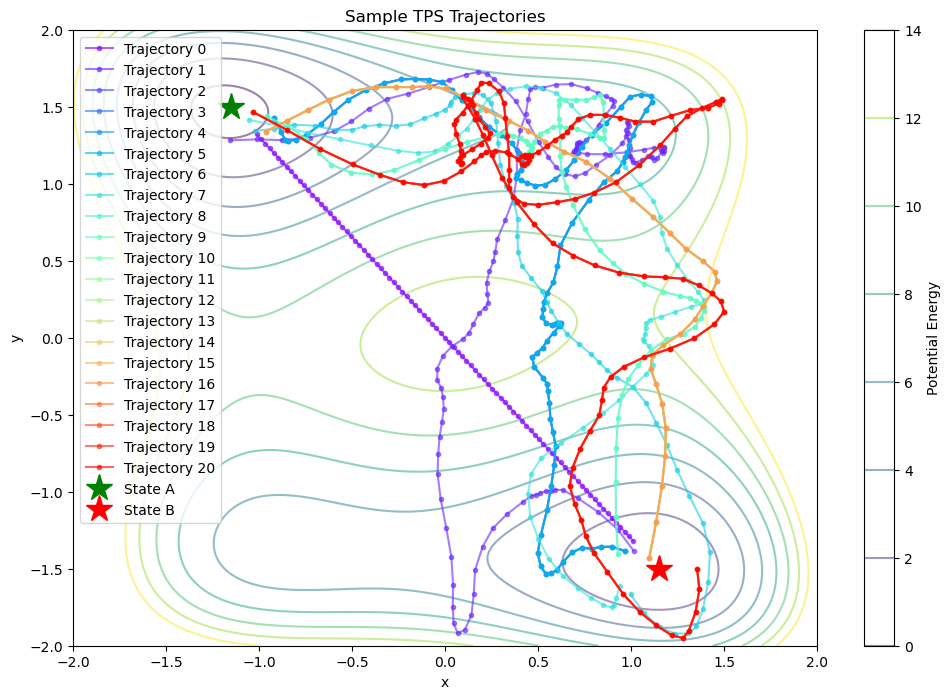


Trajectory plot complete!


In [9]:
# Plot trajectories on the PES
plt.figure(figsize=(12, 8))

# Plot PES
contours = plt.contour(X, Y, U, levels=pes.levels, cmap='viridis', alpha=0.5)
plt.colorbar(contours, label='Potential Energy')

# Plot trajectories
colors = plt.cm.rainbow(np.linspace(0, 1, len(trajectories[::5])))
for i, traj in enumerate(trajectories[::5]):
    coords = np.array([snapshot.xyz[0][:2] for snapshot in traj])
    plt.plot(coords[:, 0], coords[:, 1], 'o-', alpha=0.6, color=colors[i], 
             label=f'Trajectory {i}', markersize=3)

# Mark states
if len(pes.state_A) == 2 and len(pes.state_B) == 2:
    plt.plot(pes.state_A[0], pes.state_A[1], 'g*', markersize=20, label='State A')
    plt.plot(pes.state_B[0], pes.state_B[1], 'r*', markersize=20, label='State B')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Sample TPS Trajectories')
plt.legend()
plt.show()

print("\nTrajectory plot complete!")

## 9. Clean Up

In [10]:
# Close storage
storage.close()
print(f"Storage closed: {storage_file}")

Storage closed: toy_tps_example.nc
